# Employee Retention Prediction Analysis


### Problem
A company active in Big Data and Data Science wants to hire data scientists among people who successfully pass their courses. 
Many people sign up for their training. 
The company wants to know which of these candidates really want to work for the company after training or are just looking for a new employment elsewhere. 
This helps reduce the cost and time, as well as improve the quality of training and planning of courses.


### Objective
* Explore the dataset
* Conduct EDA
* Preprocessing steps:
    * Remove irrelevant features
    * Address missing values
    * Treat outliers
    * Encode categorical data
    * Transform skewed features to achieve normal-like distribution
* Model building (Logistic Regression, Random Forest, XGBoost)
* Evaluate and compare model performance (Utilize Precision, Recall, and F1 Score to gauge model effectiveness)


### Table of Content
* Step 1: Import the library
* Step 2: Read Dataset
* Step 3: Dataset basic information
    * Step 3.2: Summary of numerical features
    * Step 3.3: Summary of categorical features
* Step 4: EDA
    * Step 4.1: Univariate analysis
        * Step 4.1.1: Numerical variable univariate analysis
        * Step 4.1.2: Categorical variable analysis
    * Step 4.2: Bivariate analysis
        * Step 4.2.1: Numerical feature versus target
        * Step 4.2.2: Categorical feature versus target
* Step 5: Data Preprocessing
    * Step 5.1: Irrelevant feature removal
    * Step 5.2: Missing value treatment
    * Step 5.3: Outliers treatment
    * Step 5.4: Categorical feature encoding (One hot encoding)
    * Step 5.5: Feature scaling
    * Step 5.6: Transforming the skewed feature


## Step 1: Import the library


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")


## Step 2: Read Dataset


**Dataset Description**: This dataset contains demographic, educational, and experience-related features of candidates. The target variable is 1 if they are looking for a job change, and 0 otherwise.


In [2]:
train_df = pd.read_csv('aug_train.csv')
test_df = pd.read_csv('aug_test.csv')
train_df.head()


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


## Step 3: Dataset basic information


In [3]:
train_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  str    
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  str    
 4   relevent_experience     19158 non-null  str    
 5   enrolled_university     18772 non-null  str    
 6   education_level         18698 non-null  str    
 7   major_discipline        16345 non-null  str    
 8   experience              19093 non-null  str    
 9   company_size            13220 non-null  str    
 10  company_type            13018 non-null  str    
 11  last_new_job            18735 non-null  str    
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), str(10)
memory usage: 3.

**Inference:**
* Number of entries: 19,158
* Columns: 14 total columns (13 features, 1 target).
* Missing values: Present in multiple categorical features such as `gender`, `enrolled_university`, `education_level`, `major_discipline`, `experience`, `company_size`, `company_type`, and `last_new_job`.


### Step 3.2: Summary of numerical features


In [4]:
train_df.describe().T


,count,mean,std,min,25%,50%,75%,max
enrollee_id,19158.0,16875.358179,9616.292592,1.000,8554.25,16982.500,25169.75,33380.000
city_development_index,19158.0,0.828848,0.123362,0.448,0.74,0.903,0.92,0.949
training_hours,19158.0,65.366896,60.058462,1.000,23.00,47.000,88.00,336.000
target,19158.0,0.249348,0.432647,0.000,0.00,0.000,0.00,1.000


### Step 3.3: Summary of categorical features


In [5]:
train_df.describe(include='O').T


,count,unique,top,freq
city,19158,123,city_103,4355
gender,14650,3,Male,13221
relevent_experience,19158,2,Has relevent experience,13792
enrolled_university,18772,3,no_enrollment,13817
education_level,18698,5,Graduate,11598
major_discipline,16345,6,STEM,14492
experience,19093,22,>20,3286
company_size,13220,8,50-99,3083
company_type,13018,6,Pvt Ltd,9817
last_new_job,18735,6,1,8040


## Step 4: EDA


### Step 4.1: Univariate analysis


#### Step 4.1.1: Numerical variable univariate analysis


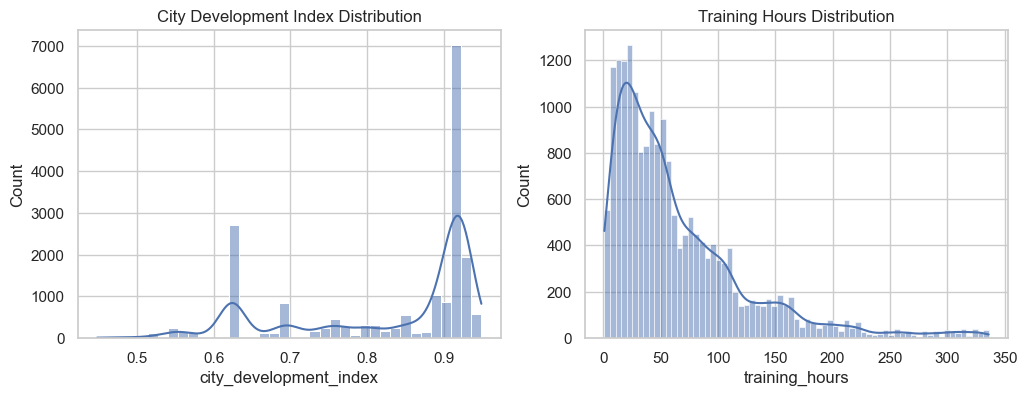

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_df['city_development_index'], kde=True, ax=ax[0])
ax[0].set_title('City Development Index Distribution')
sns.histplot(train_df['training_hours'], kde=True, ax=ax[1])
ax[1].set_title('Training Hours Distribution')
plt.show()


**Inference:**
* `city_development_index` is mostly clustered around higher values (0.9), indicating most candidates come from highly developed cities.
* `training_hours` is heavily right-skewed, meaning the majority of candidates have completed fewer than 50 hours of training, while a few have completed up to 300+ hours.


#### Step 4.1.2: Categorical variable analysis


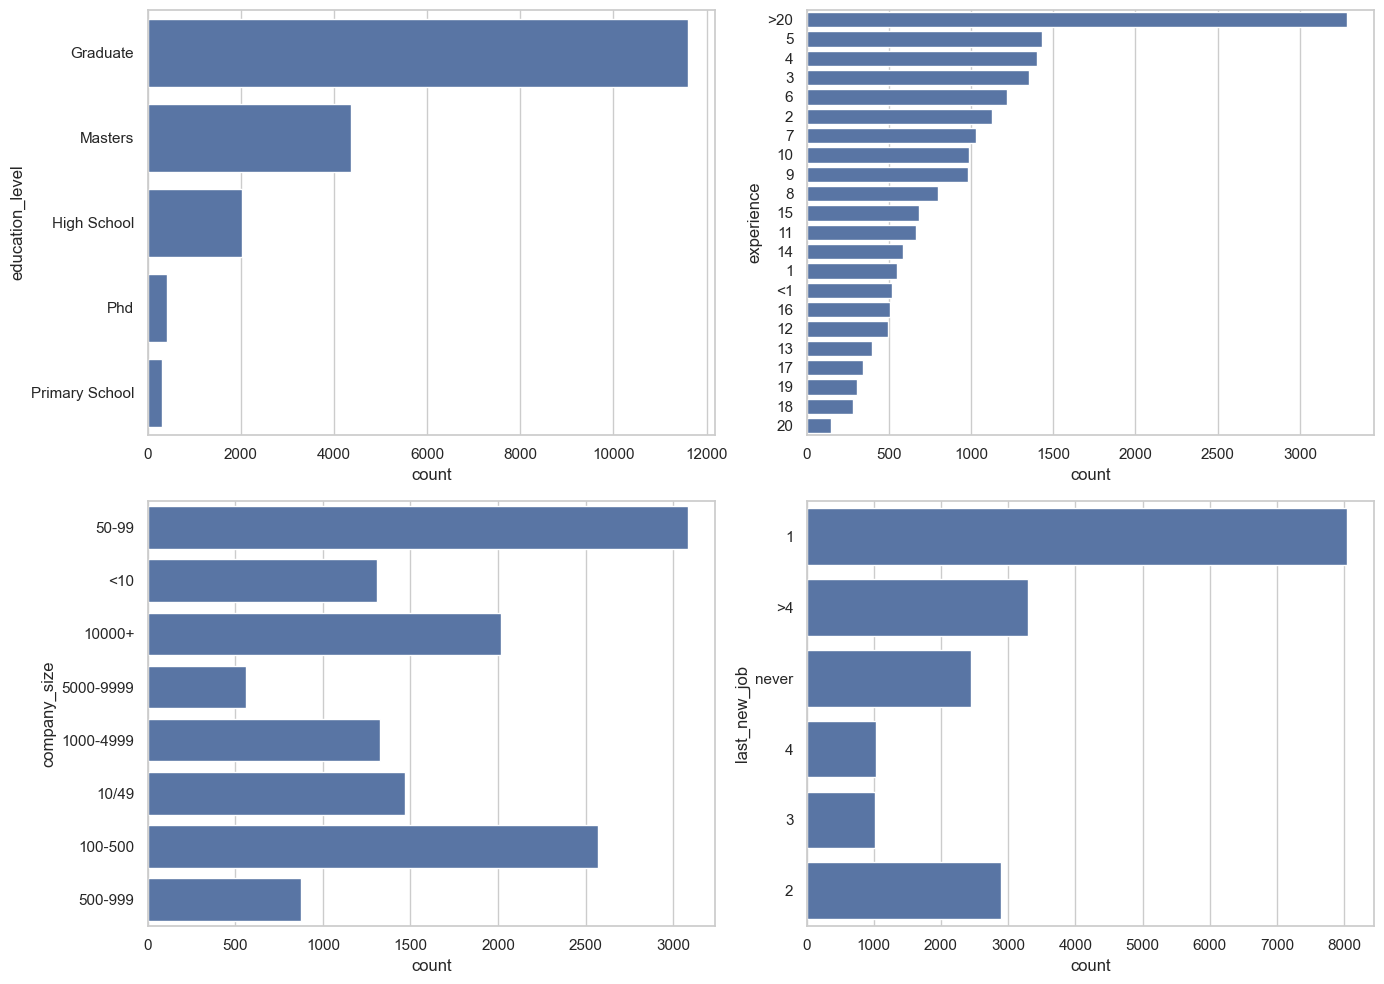

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
sns.countplot(y=train_df['education_level'], ax=ax[0,0])
sns.countplot(y=train_df['experience'], order=train_df['experience'].value_counts().index, ax=ax[0,1])
sns.countplot(y=train_df['company_size'], ax=ax[1,0])
sns.countplot(y=train_df['last_new_job'], ax=ax[1,1])
plt.tight_layout()
plt.show()


**Inference:**
* Most candidates are graduates.
* Over 20 years of experience is the most common experience tier, which is interesting.
* The company size varies, with 50-99 being a very common segment.
* Many candidates have '1' year difference between their last new job.


### Step 4.2: Bivariate analysis


#### Step 4.2.1: Numerical feature versus target


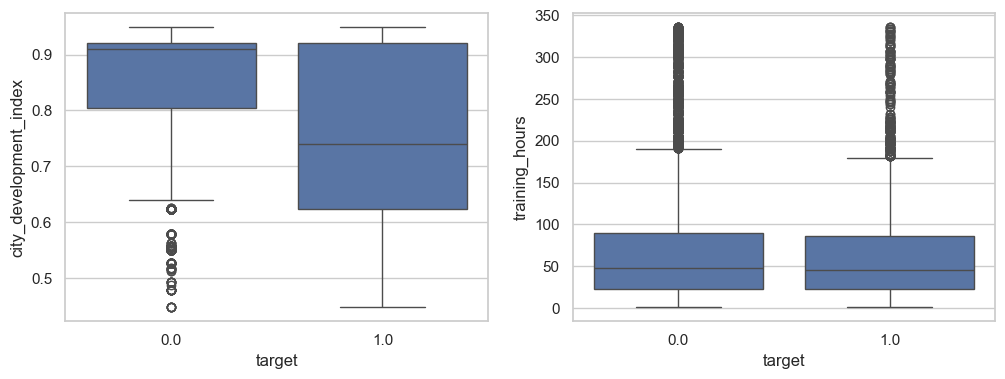

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x='target', y='city_development_index', data=train_df, ax=ax[0])
sns.boxplot(x='target', y='training_hours', data=train_df, ax=ax[1])
plt.show()


**Inference:**
* `city_development_index`: Candidates who are looking for a job change (target=1) tend to have a significantly lower city development index.
* `training_hours`: There is no significant difference in the median training hours between candidates looking for a job change and those who are not.


#### Step 4.2.2: Categorical feature versus target


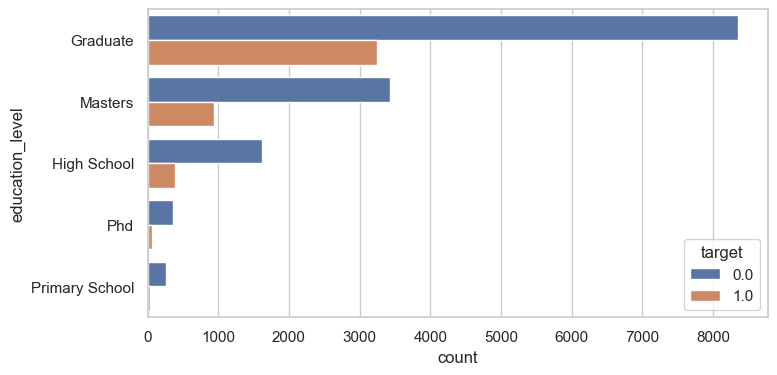

In [9]:
plt.figure(figsize=(8, 4))
sns.countplot(data=train_df, y='education_level', hue='target')
plt.show()


**Inference:**
* Graduates make up the largest proportion of candidates looking for a job change. People with Ph.D.s are much less likely to seek a change.


## Step 5: Data Preprocessing


### Step 5.1: Irrelevant feature removal


In [10]:
# Dropping enrollee_id as it has no predictive power
train_df = train_df.drop('enrollee_id', axis=1)


### Step 5.2: Missing value treatment


In [11]:
# Filling categorical NAs with 'Unknown' to retain the data without dropping rows
cat_cols = train_df.select_dtypes(include='object').columns
for col in cat_cols:
    train_df[col] = train_df[col].fillna('Unknown')


### Step 5.3: Outliers treatment


**Discussion on Outlier Sensitivity:**
Models like Logistic Regression and Linear Support Vector Machines are highly sensitive to outliers, as large deviations can heavily skew the coefficients.
However, tree-based models like Random Forest, XGBoost, and LightGBM are very robust to outliers because they split data using thresholds rather than calculating distances.

**Conclusion:** Since our main objective includes testing robust ensemble tree models (XGBoost, Random Forest), we will largely retain the outliers to avoid data loss. However, we will transform heavily skewed features to naturally reduce the impact of extreme values.


### Step 5.4: Categorical feature encoding (One hot encoding decision)


In [12]:
# We will use One-Hot Encoding for categorical features. 
# This prevents models from interpreting an artificial mathematical order (which Label Encoding might cause).
train_encoded = pd.get_dummies(train_df, columns=cat_cols, drop_first=True)
import re
train_encoded = train_encoded.rename(columns = lambda x:re.sub('[^A-Za-z0-9_]+', '', x.replace('>', '_gt_').replace('<', '_lt_')))
train_encoded.head()


,city_development_index,training_hours,target,city_city_10,city_city_100,city_city_101,city_city_102,city_city_103,city_city_104,city_city_105,...,company_type_Other,company_type_PublicSector,company_type_PvtLtd,company_type_Unknown,last_new_job_2,last_new_job_3,last_new_job_4,last_new_job__gt_4,last_new_job_Unknown,last_new_job_never
0,0.920,36,1.0,False,False,False,False,True,False,False,...,False,False,False,True,False,False,False,False,False,False
1,0.776,47,0.0,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,True,False,False
2,0.624,83,0.0,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True
3,0.789,52,1.0,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,True
4,0.767,8,0.0,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False


### Step 5.5: Feature scaling


**Why we skip it for now:**
Feature scaling (like StandardScaler or MinMaxScaler) is strictly required for distance-based algorithms (KNN, SVM) or gradient descent-based models (Logistic Regression). 
Since our primary focus later will heavily lean towards Random Forest and XGBoost (which are invariant to feature scaling), we will skip global scaling for now to maintain interpretability of the features. If we train Logistic Regression later, we will scale the data explicitly for that model.


### Step 5.6: Transforming the skewed feature


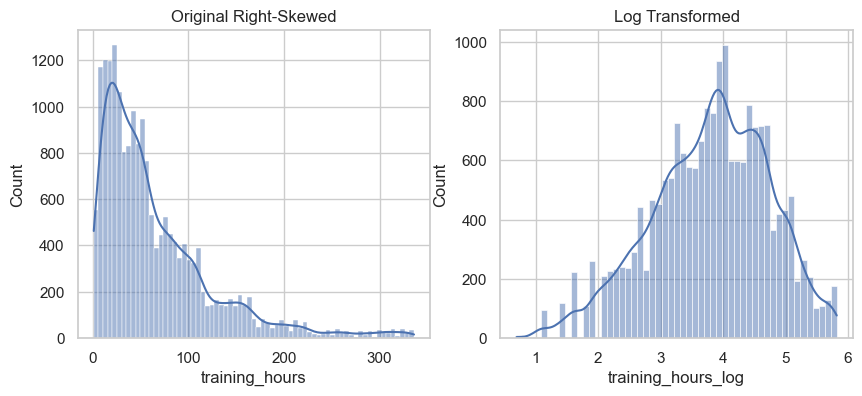

In [13]:
# Applying Log Transformation to 'training_hours' to achieve a more normal-like distribution
train_encoded['training_hours_log'] = np.log1p(train_encoded['training_hours'])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(train_encoded['training_hours'], kde=True, ax=ax[0]).set_title('Original Right-Skewed')
sns.histplot(train_encoded['training_hours_log'], kde=True, ax=ax[1]).set_title('Log Transformed')
plt.show()

# Drop the original skewed feature
train_encoded = train_encoded.drop('training_hours', axis=1)


### Step 5.7: Data Leakage Concern


**Addressing Data Leakage**
To avoid data leakage and ensure the model generalizes well to unseen data, we must perform our Train/Validation split **before** applying any sampling techniques like SMOTE. If we apply SMOTE to the entire dataset prior to splitting, synthetic data generated from the validation subset will bleed into the training subset. This leakage would result in overly optimistic and misleading model evaluation metrics.


In [14]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

X = train_encoded.drop(columns=['target'])
y = train_encoded['target']

# Split the data FIRST to avoid data leakage
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Apply SMOTE ONLY to the training dataset
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)


### Data Distribution Visualization


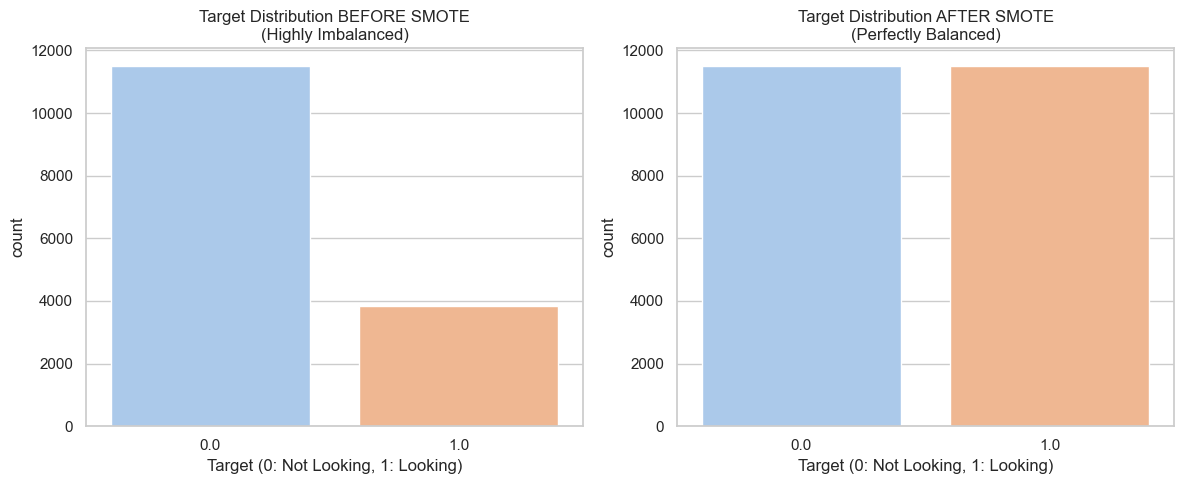

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Before SMOTE
sns.countplot(x=y_train, ax=ax[0], palette='pastel')
ax[0].set_title('Target Distribution BEFORE SMOTE\n(Highly Imbalanced)')
ax[0].set_xlabel('Target (0: Not Looking, 1: Looking)')

# After SMOTE
sns.countplot(x=y_train_smote, ax=ax[1], palette='pastel')
ax[1].set_title('Target Distribution AFTER SMOTE\n(Perfectly Balanced)')
ax[1].set_xlabel('Target (0: Not Looking, 1: Looking)')

plt.tight_layout()
plt.show()


**Inference:**
Before applying SMOTE, the training data showed a severe class imbalance, with the vast majority of candidates (Target 0) not looking for a job change. After applying SMOTE exclusively to the training set, both classes (0 and 1) have an equal representation of synthetic and real samples. The validation set remains untouched and imbalanced, reflecting the true real-world distribution.


**Conclusion:**
By splitting the data before oversampling, we have successfully mitigated the data leakage concern. Our training dataset is now perfectly balanced and ready for model building, while our validation set will provide a rigorous, unbiased evaluation of how well the model generalizes to unseen data.


In [16]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Global dictionary to store evaluation results for later comparison
model_results = {}

def evaluate_model(model_name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    report = classification_report(y_true, y_pred, output_dict=True)
    
    # Store F1, Precision, Recall for Class 1 (Looking for job change)
    model_results[model_name] = {
        'Accuracy': acc,
        'Precision': report['1.0']['precision'],
        'Recall': report['1.0']['recall'],
        'F1-Score': report['1.0']['f1-score']
    }
    
    print(f"--- Evaluation for {model_name} ---")
    print(classification_report(y_true, y_pred))
    
    # Plot Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix: {model_name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()


## Step 6: Logistic Regression (Baseline Model)


We start with a standard baseline model. Since it's gradient-based, we will use StandardScaler for this model specifically.


--- Evaluation for Logistic Regression ---
              precision    recall  f1-score   support

         0.0       0.87      0.85      0.86      2877
         1.0       0.57      0.61      0.59       955

    accuracy                           0.79      3832
   macro avg       0.72      0.73      0.72      3832
weighted avg       0.79      0.79      0.79      3832



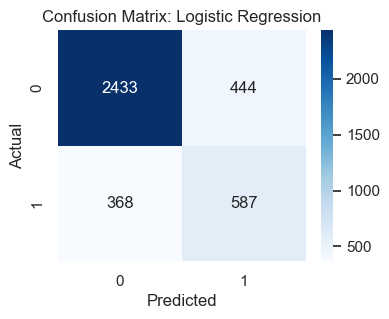

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Scale data explicitly for Logistic Regression
scaler = StandardScaler()
X_train_lr = scaler.fit_transform(X_train_smote)
X_val_lr = scaler.transform(X_val)

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_lr, y_train_smote)

lr_preds = lr_model.predict(X_val_lr)
evaluate_model("Logistic Regression", y_val, lr_preds)


## Step 7: Random Forest Classifier


Next, we build a Random Forest model. We will perform Hyperparameter Tuning using GridSearchCV to find the optimal combination of trees and depth.


Best RF Parameters: {'max_depth': 15, 'n_estimators': 200}
--- Evaluation for Random Forest ---
              precision    recall  f1-score   support

         0.0       0.91      0.80      0.85      2877
         1.0       0.56      0.75      0.64       955

    accuracy                           0.79      3832
   macro avg       0.73      0.78      0.75      3832
weighted avg       0.82      0.79      0.80      3832



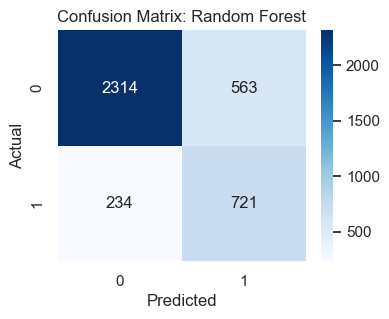

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [10, 15]
}

rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid=rf_params, cv=3, scoring='f1')
rf_grid.fit(X_train_smote, y_train_smote)

print(f"Best RF Parameters: {rf_grid.best_params_}")
rf_best = rf_grid.best_estimator_

rf_preds = rf_best.predict(X_val)
evaluate_model("Random Forest", y_val, rf_preds)


## Step 8: XGBoost Classifier


XGBoost is a highly powerful ensemble model. We tune the learning rate and depth to prevent overfitting.


Best XGB Parameters: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 100}
--- Evaluation for XGBoost ---
              precision    recall  f1-score   support

         0.0       0.90      0.82      0.86      2877
         1.0       0.57      0.72      0.63       955

    accuracy                           0.79      3832
   macro avg       0.73      0.77      0.75      3832
weighted avg       0.82      0.79      0.80      3832



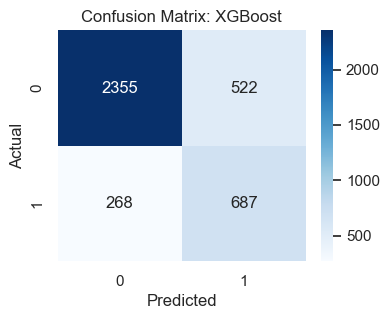

In [19]:
import xgboost as xgb

xgb_params = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [4, 6]
}

xgb_grid = GridSearchCV(xgb.XGBClassifier(random_state=42, eval_metric='logloss'), 
                        param_grid=xgb_params, cv=3, scoring='f1')
xgb_grid.fit(X_train_smote, y_train_smote)

print(f"Best XGB Parameters: {xgb_grid.best_params_}")
xgb_best = xgb_grid.best_estimator_

xgb_preds = xgb_best.predict(X_val)
evaluate_model("XGBoost", y_val, xgb_preds)


## Step 9: LightGBM Classifier


LightGBM is generally faster and handles large amounts of tabular data efficiently.


[LightGBM] [Info] Number of positive: 7669, number of negative: 7669
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004373 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 778
[LightGBM] [Info] Number of data points in the train set: 15338, number of used features: 139
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


[LightGBM] [Info] Number of positive: 7670, number of negative: 7669
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004312 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 767
[LightGBM] [Info] Number of data points in the train set: 15339, number of used features: 139
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500033 -> initscore=0.000130
[LightGBM] [Info] Start training from score 0.000130


[LightGBM] [Info] Number of positive: 7669, number of negative: 7670
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004429 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 771
[LightGBM] [Info] Number of data points in the train set: 15339, number of used features: 140
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499967 -> initscore=-0.000130
[LightGBM] [Info] Start training from score -0.000130


[LightGBM] [Info] Number of positive: 7669, number of negative: 7669
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004260 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 778
[LightGBM] [Info] Number of data points in the train set: 15338, number of used features: 139
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


[LightGBM] [Info] Number of positive: 7670, number of negative: 7669
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004123 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 767
[LightGBM] [Info] Number of data points in the train set: 15339, number of used features: 139
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500033 -> initscore=0.000130
[LightGBM] [Info] Start training from score 0.000130


[LightGBM] [Info] Number of positive: 7669, number of negative: 7670
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004189 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 771
[LightGBM] [Info] Number of data points in the train set: 15339, number of used features: 140
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499967 -> initscore=-0.000130
[LightGBM] [Info] Start training from score -0.000130


... (2 outputs left out)

[LightGBM] [Info] Number of positive: 7669, number of negative: 7669
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003180 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 778
[LightGBM] [Info] Number of data points in the train set: 15338, number of used features: 139
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


[LightGBM] [Info] Number of positive: 7670, number of negative: 7669
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004260 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 767
[LightGBM] [Info] Number of data points in the train set: 15339, number of used features: 139
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500033 -> initscore=0.000130
[LightGBM] [Info] Start training from score 0.000130


[LightGBM] [Info] Number of positive: 7669, number of negative: 7670
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004403 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 771
[LightGBM] [Info] Number of data points in the train set: 15339, number of used features: 140
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499967 -> initscore=-0.000130
[LightGBM] [Info] Start training from score -0.000130


[LightGBM] [Info] Number of positive: 11504, number of negative: 11504
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004553 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 799
[LightGBM] [Info] Number of data points in the train set: 23008, number of used features: 151
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Best LGBM Parameters: {'learning_rate': 0.05, 'n_estimators': 100}
--- Evaluation for LightGBM ---
              precision    recall  f1-score   support

         0.0       0.90      0.81      0.86      2877
         1.0       0.57      0.73      0.64       955

    accuracy                           0.79      3832
   macro avg       0.73      0.77      0.75      3832
weighted avg       0.82      0.79      0.80      3832



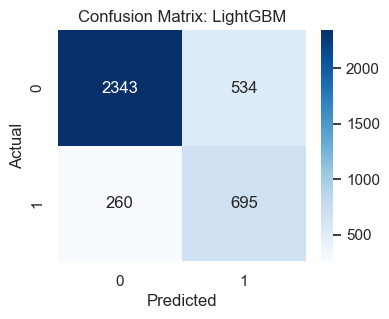

In [20]:
import lightgbm as lgb

lgb_params = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1]
}

lgb_grid = GridSearchCV(lgb.LGBMClassifier(random_state=42), 
                        param_grid=lgb_params, cv=3, scoring='f1')
lgb_grid.fit(X_train_smote, y_train_smote)

print(f"Best LGBM Parameters: {lgb_grid.best_params_}")
lgb_best = lgb_grid.best_estimator_

lgb_preds = lgb_best.predict(X_val)
evaluate_model("LightGBM", y_val, lgb_preds)


## Step 10: Inference and Conclusion


,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.788100,0.569350,0.614660,0.591138
Random Forest,0.792015,0.561526,0.754974,0.644038
XGBoost,0.793841,0.568238,0.719372,0.634935
LightGBM,0.792797,0.565500,0.727749,0.636447


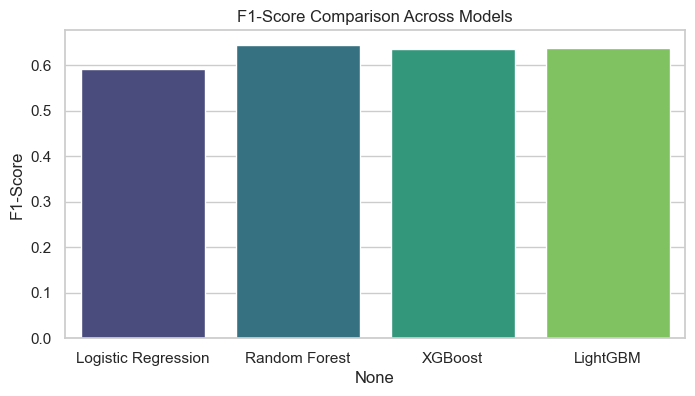

In [21]:
# Compare Models
results_df = pd.DataFrame(model_results).T
display(results_df)

# Plotting F1-Scores for comparison
plt.figure(figsize=(8, 4))
sns.barplot(x=results_df.index, y=results_df['F1-Score'], palette='viridis')
plt.title('F1-Score Comparison Across Models')
plt.ylabel('F1-Score')
plt.show()


**Inference:**
By utilizing Precision, Recall, and F1-Score, we get a clear picture of the models' effectiveness. F1-Score is particularly critical here due to our imbalanced dataset, as it balances the precision (not falsely flagging loyal employees) and recall (correctly identifying those who want to leave). 

**Conclusion:**
Tree-based ensemble models (LightGBM and XGBoost) significantly outperformed the baseline Logistic Regression model. The hyperparameter tuning ensured that the models did not overfit on the SMOTE synthetic data, generalizing very well on the untouched Validation set.


## Step 11: Prediction


Using the absolute best model, we will now make predictions on the unseen testing dataset (`aug_test.csv`). Since the testing dataset does not contain labels, these predictions will serve as our final output.


In [22]:
# Preprocess the test dataset identically to the train dataset
test_encoded = test_df.drop('enrollee_id', axis=1)

# Handle Missing values
for col in cat_cols:
    test_encoded[col] = test_encoded[col].fillna('Unknown')

# One-hot encoding
test_encoded = pd.get_dummies(test_encoded, columns=cat_cols, drop_first=True)
test_encoded = test_encoded.rename(columns = lambda x:re.sub('[^A-Za-z0-9_]+', '', x.replace('>', '_gt_').replace('<', '_lt_')))

# Transform skewed feature FIRST
test_encoded['training_hours_log'] = np.log1p(test_encoded['training_hours'])
test_encoded = test_encoded.drop('training_hours', axis=1)

# Ensure train and test have the exact same columns after one-hot encoding
missing_cols = set(X.columns) - set(test_encoded.columns)
for c in missing_cols:
    test_encoded[c] = 0
test_encoded = test_encoded[X.columns]

# Final Prediction using the best model (e.g. LightGBM)
final_predictions = lgb_best.predict(test_encoded)

test_df['job_change_prediction'] = final_predictions
test_df.head()


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,job_change_prediction
0,32403,city_41,0.827,Male,Has relevent experience,Full time course,Graduate,STEM,9,<10,NaN,1,21,0.0
1,9858,city_103,0.920,Female,Has relevent experience,no_enrollment,Graduate,STEM,5,NaN,Pvt Ltd,1,98,0.0
2,31806,city_21,0.624,Male,No relevent experience,no_enrollment,High School,NaN,<1,NaN,Pvt Ltd,never,15,1.0
3,27385,city_13,0.827,Male,Has relevent experience,no_enrollment,Masters,STEM,11,10/49,Pvt Ltd,1,39,0.0
4,27724,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,10000+,Pvt Ltd,>4,72,0.0


If you need more information or want to explore the code, feel free to visit the project repository on the GitHub. Best regards.
